# CNN (Convolutional Neural Network)

Se realiza el estudio y diseño de la arquitectura convolucional para el analisis de eventos de caidas en señales inerciales de tres ejes.



In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras import layers, losses
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers

# Configuración de rutas del proyecto
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

from src.utils import *
from src.models import *

In [2]:
autoencoder = Autoencoder()

autoencoder.set_coef(str(MODELS_DIR / "coeficientes" / "coeficientes_encoder.csv"), "encoder")
autoencoder.set_coef(str(MODELS_DIR / "coeficientes" / "coeficientes_decoder.csv"), "decoder")

Leyendo coeficientes desde: c:\Users\guido\Documents\Paper - Deteccion de caidas\Fall_detection\models\coeficientes\coeficientes_encoder.csv...
 [+] Coeficientes cargados con éxito en la capa: CONV1_16
 [+] Coeficientes cargados con éxito en la capa: CONV2_32
 [+] Coeficientes cargados con éxito en la capa: CONV3_64
 [+] Coeficientes cargados con éxito en la capa: CONV4_128

Proceso finalizado. Se actualizaron 4 capas.
Leyendo coeficientes desde: c:\Users\guido\Documents\Paper - Deteccion de caidas\Fall_detection\models\coeficientes\coeficientes_decoder.csv...
 [+] Coeficientes cargados con éxito en la capa: DECONV1
 [+] Coeficientes cargados con éxito en la capa: DECONV2
 [+] Coeficientes cargados con éxito en la capa: DECONV3
 [+] Coeficientes cargados con éxito en la capa: DECONV4

Proceso finalizado. Se actualizaron 4 capas.


In [3]:
## Levanto el dataset (unicamente los datos de acelerometro)
data_full = extraer_datos_csv(path=str(DATA_DIR / 'outputs_FallAI_Dataset'), file = 'Event_FallAIIDDataSet_*.txt', sensors= ['AccX','AccY','AccZ'])
data_full.shape

## Extraigo los Tags del dataset
tags_full, activity_full = extraer_tags_csv(path=str(DATA_DIR / 'outputs_FallAI_Dataset'), file = 'Event_FallAIIDDataSet_*.txt')

print(f"El shape de data es: {data_full.shape}")
print(f"El shape de tags es: {tags_full.shape}")


El shape de data es: (2515, 520, 3)
El shape de tags es: (2515,)


In [4]:
# Agrega la dimension para coincidir con el input
data_full = np.expand_dims(data_full, axis=-1)

## Separo datos en entrenamiento y validacion
data, data_val, tags, y_val, activity, activity_val = train_test_split(data_full,tags_full, activity_full, test_size=0.2, random_state=21)

In [5]:

print(f"Shape datos_entrenamiento {data.shape}")

# obtengo datos de prueba, de entrenamiento y validacion.

data_train, data_test, y_train, y_test, _ , activity_test = train_test_split(data,tags,activity, test_size=0.25, random_state=21)

print(f"Shape data_train: {data_train.shape}")
print(f"Shape data_test: {data_test.shape}")
print(f"Shape y_train: {len(y_train)}")
print(f"Shape y_test: {len(y_test)}")

Shape datos_entrenamiento (2012, 520, 3, 1)
Shape data_train: (1509, 520, 3, 1)
Shape data_test: (503, 520, 3, 1)
Shape y_train: 1509
Shape y_test: 503


In [6]:
neuralnetwork = NN()

c:\Users\guido\Documents\Paper - Deteccion de caidas\Fall_detection\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [7]:
## Enlazo el encoder con la red neuronal

autoencoder.encoder.trainable = False; ## false -> Congela los datos del encoder para que no se modifiquen

normalizador_entrada = layers.Normalization() # -> Creo una capa inicial que normaliza los inputs. Obtiene media y desvio del dataset completo (excluyo validacion para probar) 
normalizador_entrada.adapt(data)

red_cnn_completa = tf.keras.Sequential([
    normalizador_entrada,
    autoencoder.encoder, # Desacoplo el decoder
    neuralnetwork.modelNN
])

red_cnn_completa.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy', 
    metrics=[
        'accuracy',
        tf.keras.metrics.Recall(name='recall')]
)


autoencoder.encoder.summary()
neuralnetwork.summary()
red_cnn_completa.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ CONV1_16 (Conv2D)               │ (None, 518, 1, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 259, 1, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CONV2_32 (Conv2D)               │ (None, 257, 1, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 129, 1, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CONV3_64 (Conv2D)               │ (None, 127, 1, 64)     │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 1, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CONV4_128 (Conv2D)              │ (None, 62, 1, 128)     │        24,704 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,640 (127.50 KB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 32,640 (127.50 KB)

Model: "nn"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (2012, 520, 3, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 62, 1, 128)     │        32,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 1)              │        15,877 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,520 (189.54 KB)

 Trainable params: 15,877 (62.02 KB)

 Non-trainable params: 32,643 (127.52 KB)

In [8]:
## Entrenamiento de la red neuronal.

## Importante, la red debe entrenarse con el encoder acoplado.

historial_1 = red_cnn_completa.fit(data_train, y_train,
                    epochs=100,
                    validation_data=(data_test, y_test))

Epoch 1/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7773 - loss: 0.6936 - recall: 0.0292 - val_accuracy: 0.7694 - val_loss: 0.6081 - val_recall: 0.0000e+00
Epoch 2/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7952 - loss: 0.6360 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_loss: 0.5675 - val_recall: 0.0000e+00
Epoch 3/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7952 - loss: 0.6182 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_loss: 0.5424 - val_recall: 0.0000e+00
Epoch 4/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7959 - loss: 0.6048 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_loss: 0.5357 - val_recall: 0.0000e+00
Epoch 5/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7959 - loss: 0.5886 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_loss: 0.5254 - val_recall: 0.0000e+00
Epoch 6/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7959 - loss: 0.5856 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_loss

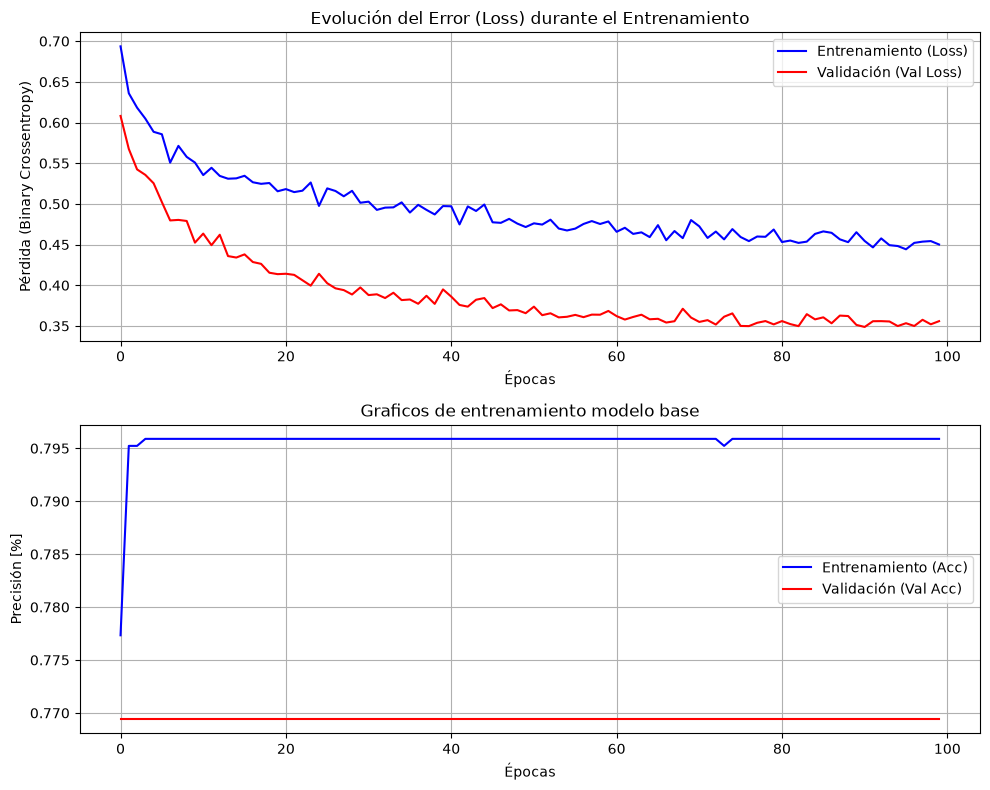

In [9]:


fig = plot_stats(history=historial_1)
plt.title("Graficos de entrenamiento modelo base")
plt.show(fig)


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


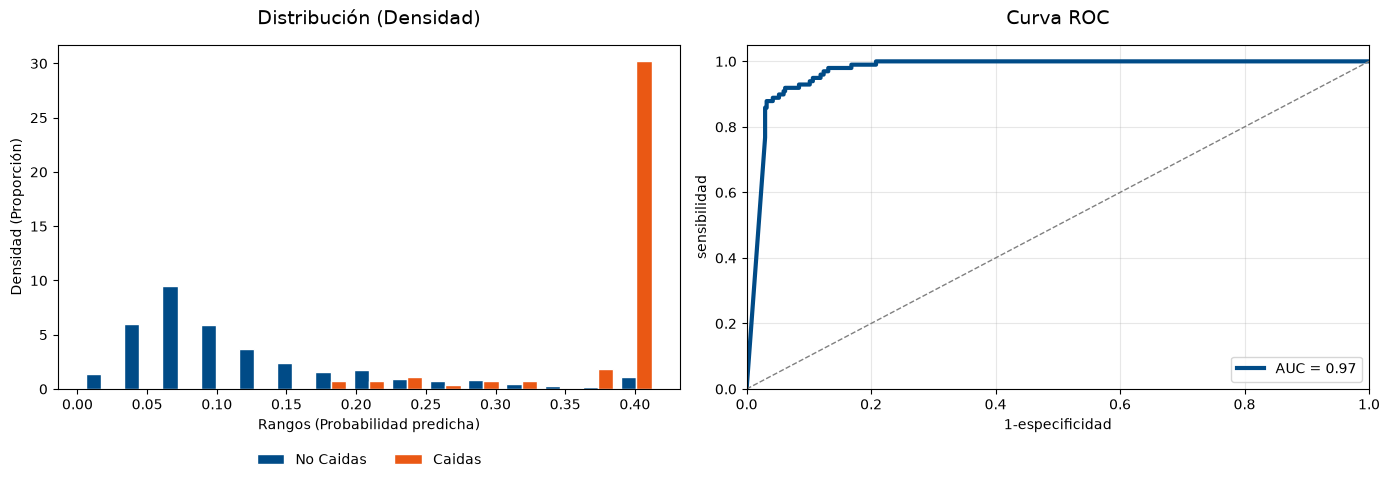

In [10]:
y_pred_acelerometro = red_cnn_completa.predict(data_val)
graficar_distribucion_y_roc(y_val,y_pred_acelerometro)  

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.97      0.94      0.96       404
    FALL (1)       0.79      0.90      0.84        99

    accuracy                           0.93       503
   macro avg       0.88      0.92      0.90       503
weighted avg       0.94      0.93      0.94       503


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    381                 23
Real CAÍDA:       10                 89


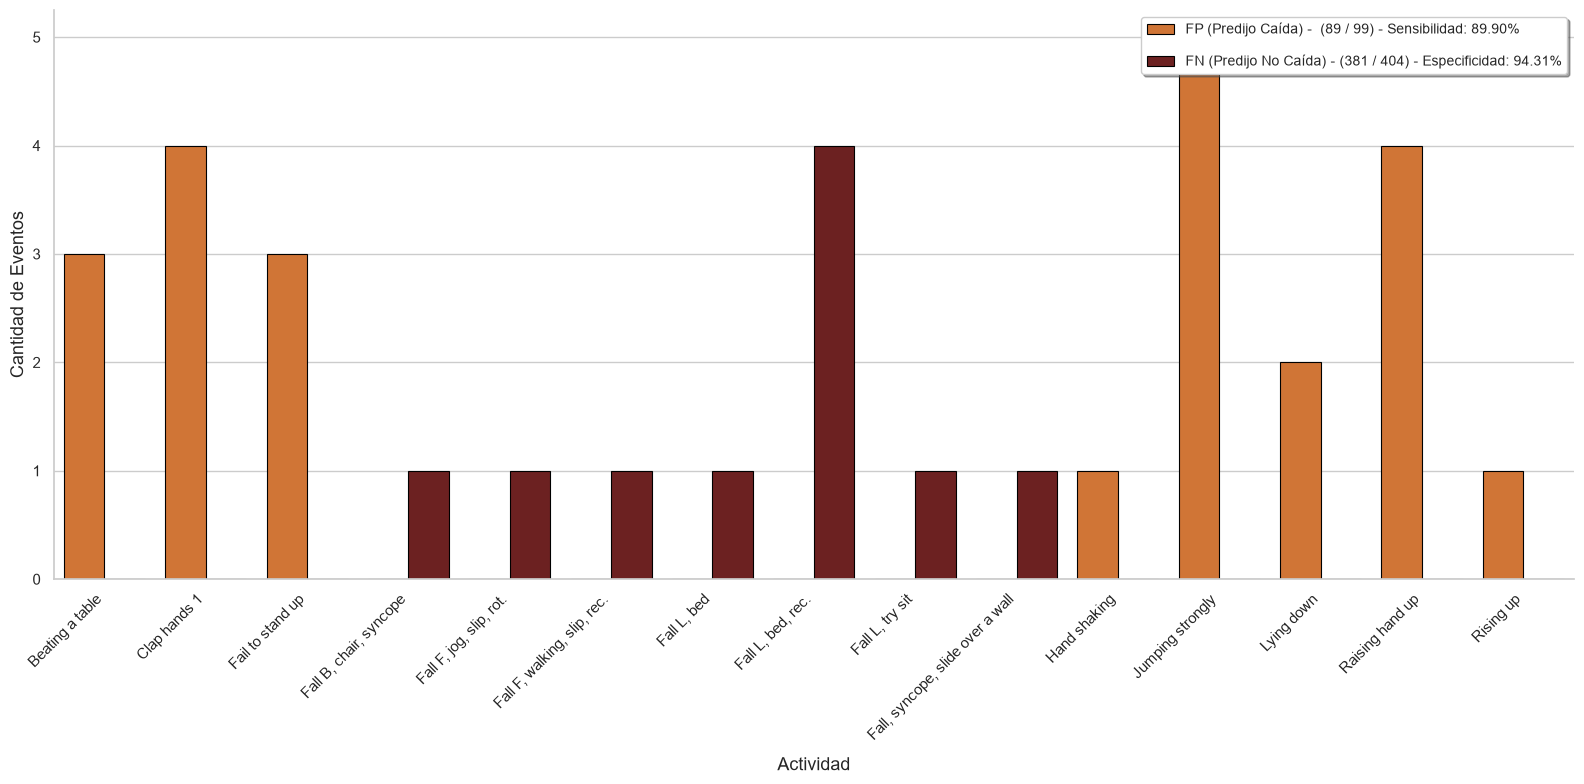

In [11]:
## Evaluando con los datos de validacion

model_perfom(red_cnn_completa, data_val, y_val,threshold= 0.3,activity_names= activity_val)
plt.show()
# red_cnn_completa.save(str(MODELS_DIR / "modelo_acelerometro2.keras"))

# Prueba de datasets cruzados

En el dataset original se tienen muestras de la muñeca, cintura y cuello, tomando en cada caso los datos de acelerometros y otros sensores. Lo que se realiza a continuacion es utilizando los datos de la cintura probar el rendimiento de la red CNN de forma de ver si estos pueden ser aprovechados dentro del dataset de entrenamiento. <br> 
Debido a la diferencia en grados de libertad entre las manos y la cintura es de esperar que no rinda tan bien como con los datos de la muñeca que fue entrenado el modelo. <br>
Otro aspecto de interes a evaluar es utilizar datos de cintura / cuello para pre-entrenar al modelo y luego hacer un fine-tunning con los datos de la muñeca.


In [12]:
## Levanto el dataset (unicamente los datos de acelerometro)
data_waist = extraer_datos_csv(path=str(DATA_DIR / 'outputs_FallAI_Dataset_Waist'), file = 'Event_FallAIIDDataSet_*.txt', sensors= ['AccX','AccY','AccZ'])

## Extraigo los Tags del dataset

tags_waist, _ = extraer_tags_csv(path=str(DATA_DIR / 'outputs_FallAI_Dataset_Waist'), file = 'Event_FallAIIDDataSet_*.txt')


print(f"El shape de data es: {data_waist.shape}")
print(f"El shape de tags es: {tags_waist.shape}")


El shape de data es: (1798, 520, 3)
El shape de tags es: (1798,)


In [13]:

## usamos el mismo escaler que se uso para los datos de muñeca.

datos_evaluacion_waist = np.expand_dims(data_waist, axis=-1)

print(f"Shape datos_entrenamiento {datos_evaluacion_waist.shape}")


Shape datos_entrenamiento (1798, 520, 3, 1)


In [14]:
model_perfom(red_cnn_completa,datos_evaluacion_waist,tags_waist,threshold= 0.3 )


57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.94      0.92      0.93      1332
    FALL (1)       0.79      0.84      0.82       466

    accuracy                           0.90      1798
   macro avg       0.87      0.88      0.87      1798
weighted avg       0.90      0.90      0.90      1798


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    1231                 101
Real CAÍDA:       76                 390


En este caso se puede ver que el cruzar los datasets da un valor menor de todos las metricas en especial la sensibilidad y exaustividad<br>
Esto es de esperar ya que estamos probando el modelo de la muñeca con datos de la cintura, en donde los sensores tienen distintos patrones de movimientos debido a la diferencia de grados de libertad. Si bien se puede observar que los datos de ambos datasets no son perfectamente compatibles, estos datos puede ser utilizados para mejorar el modelo final.<br>
Como técnica para aprovechar los datos se utilizara data aumentation una tecnica que permite aprovechar fusionar datos del datasets original con datos no reales o con ruido para la parte de entrenamiento y unicamente usar los datos del dataset de muñeca para validacion y test. Como se dispone de datos tomados en otras partes del cuerpo, los cuales no tienen la misma morfologia que los tomados en la muñeca pero si poseen patrones similares se propone incluir una porcion de ellos. Esto permitiendo buscar mayor generalidad al modelo al ser entrenado. 

## Fusion de datasets

In [15]:
# Agregamos un 40% del dataset de cintura al dataset original.

data_train_w, data_val_w, y_train_w, y_val_w = train_test_split(datos_evaluacion_waist,tags_waist, train_size= 0.6, random_state=21) 

data_train, data_test, y_train, y_test = train_test_split(data,tags, test_size=0.25, random_state=21)

print(y_train.shape)

data_train = np.concatenate([data_train, data_train_w], axis=0)
y_train = np.concatenate([y_train, y_train_w], axis=0)

print(y_train.shape)

(1509,)
(2587,)


In [16]:
# Generamos una nueva etapa de clasificacion.
neuralnetwork2 = NN()

normalizador_entrada = layers.Normalization()
normalizador_entrada.adapt(data)

model_merge_dataset = tf.keras.Sequential([
    normalizador_entrada,
    autoencoder.encoder, # Desacoplo el decoder
    neuralnetwork2.modelNN
])

model_merge_dataset.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy', 
    metrics=[
        'accuracy',
        tf.keras.metrics.Recall(name='recall')]
)

c:\Users\guido\Documents\Paper - Deteccion de caidas\Fall_detection\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [17]:

historial_2 = model_merge_dataset.fit(data_train,y_train,
                    epochs=100,
                    validation_data=(data_test, y_test))

Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7746 - loss: 0.6909 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_loss: 0.5478 - val_recall: 0.0000e+00
Epoch 2/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7746 - loss: 0.5728 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_loss: 0.4915 - val_recall: 0.0000e+00
Epoch 3/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7746 - loss: 0.5491 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_loss: 0.4748 - val_recall: 0.0000e+00
Epoch 4/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7746 - loss: 0.5296 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_loss: 0.4553 - val_recall: 0.0000e+00
Epoch 5/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7746 - loss: 0.5139 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_loss: 0.4360 - val_recall: 0.0000e+00
Epoch 6/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7746 - loss: 0.4910 - recall: 0.0000e+00 - val_accuracy: 0.7694 - val_

In [18]:
model_merge_dataset.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 520, 3, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 62, 1, 128)     │        32,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 1)              │        15,877 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,276 (313.59 KB)

 Trainable params: 15,877 (62.02 KB)

 Non-trainable params: 32,643 (127.52 KB)

 Optimizer params: 31,756 (124.05 KB)

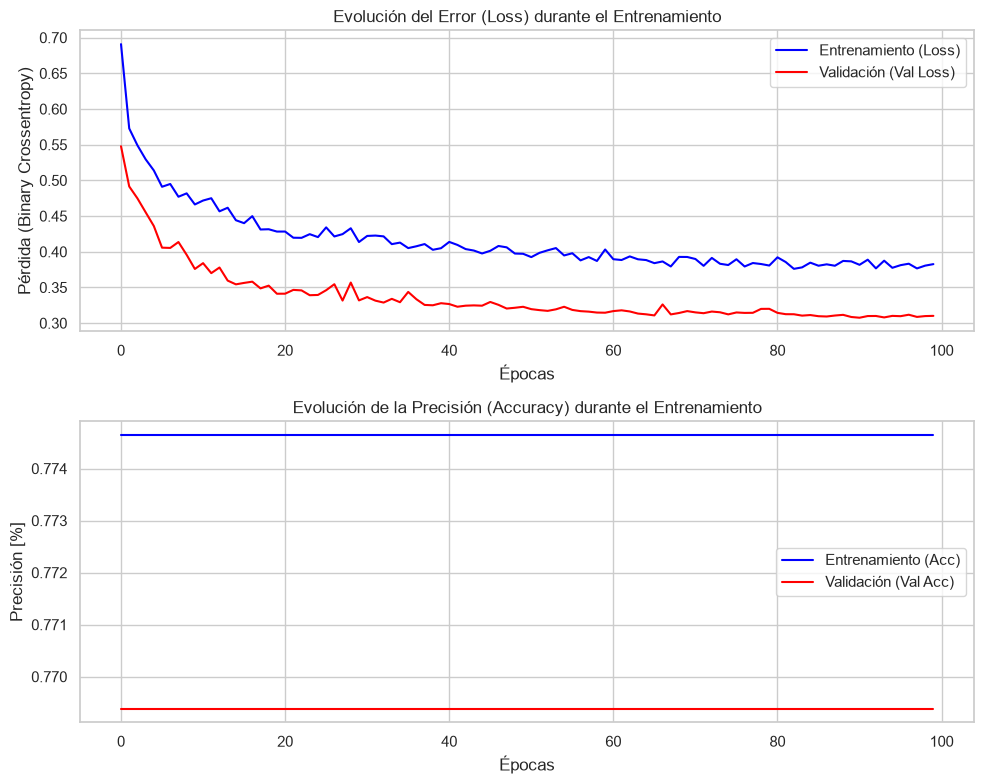

In [19]:
fig = plot_stats(history=historial_2)
plt.show(fig)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


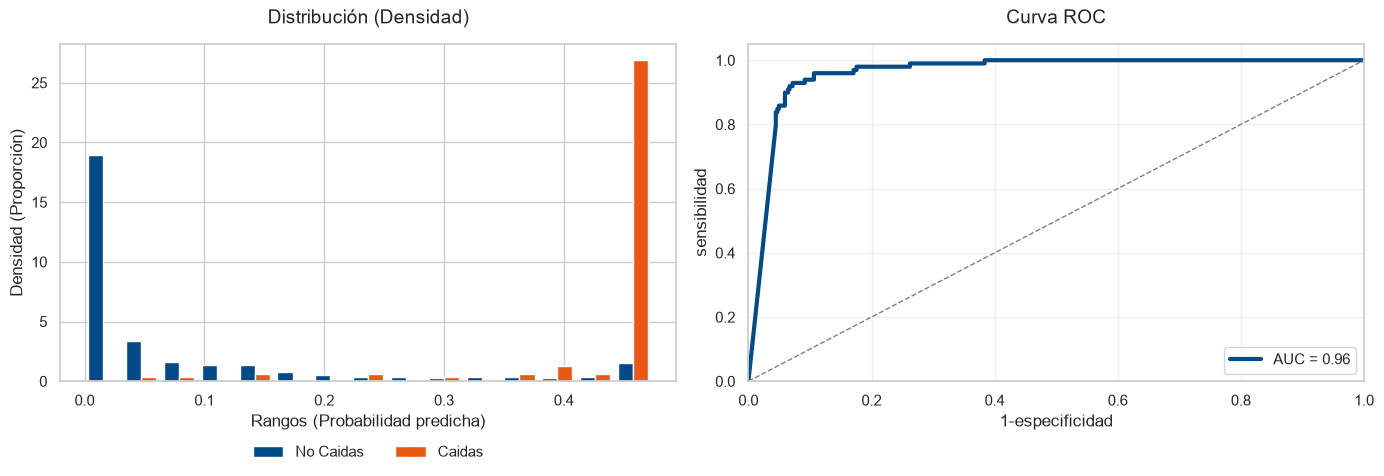

In [20]:
y_pred_acelerometro = model_merge_dataset.predict(data_val)
graficar_distribucion_y_roc(y_val,y_pred_acelerometro)  

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.98      0.90      0.94       404
    FALL (1)       0.70      0.94      0.81        99

    accuracy                           0.91       503
   macro avg       0.84      0.92      0.87       503
weighted avg       0.93      0.91      0.92       503


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    365                 39
Real CAÍDA:       6                 93


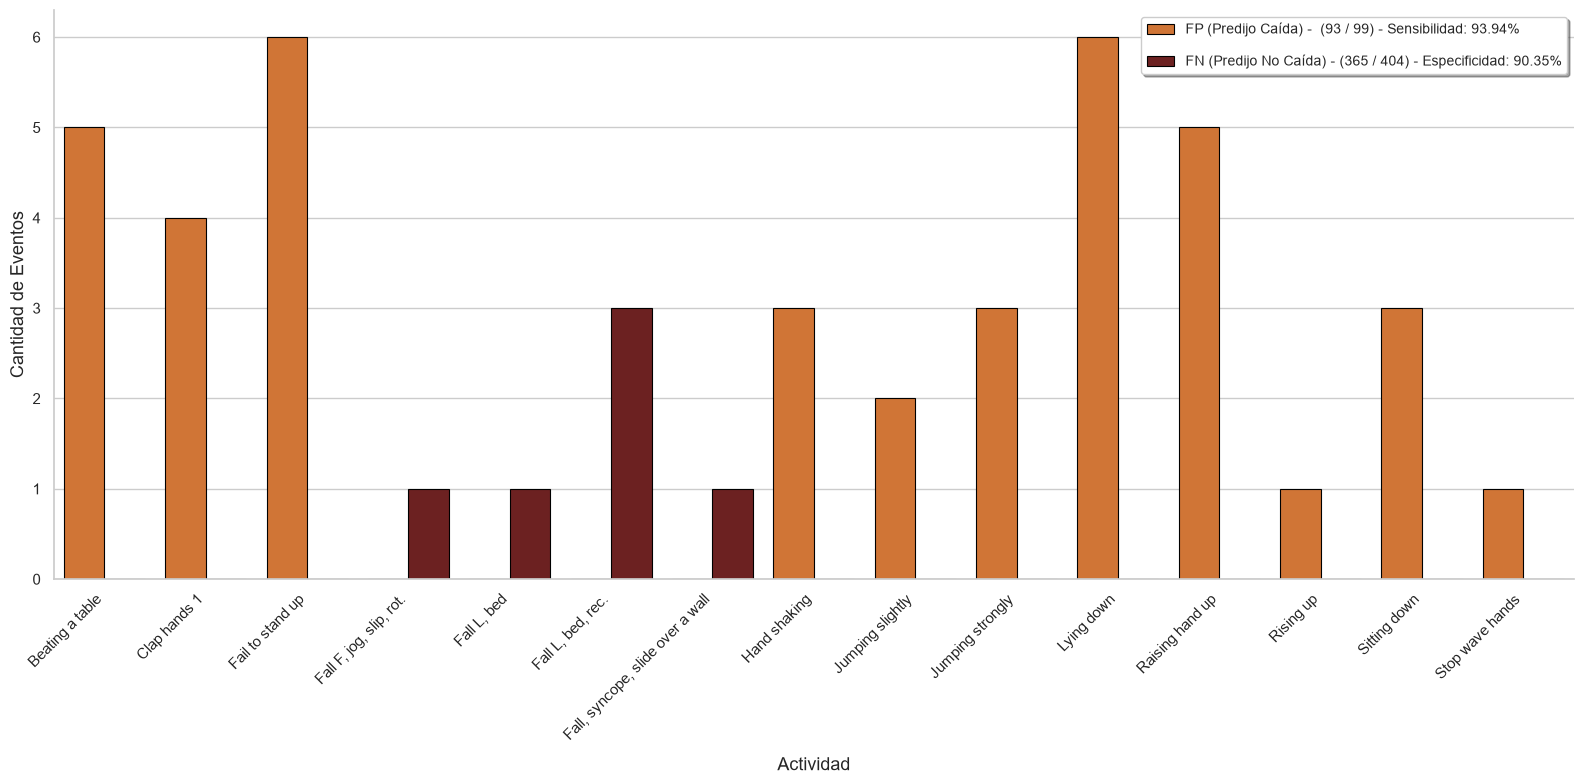

In [21]:

model_perfom(model_merge_dataset, data_val, y_val,threshold= 0.3,activity_names= activity_val)
plt.show()


79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.99      0.91      0.95      1992
    FALL (1)       0.74      0.96      0.83       523

    accuracy                           0.92      2515
   macro avg       0.86      0.93      0.89      2515
weighted avg       0.94      0.92      0.92      2515


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    1814                 178
Real CAÍDA:       23                 500


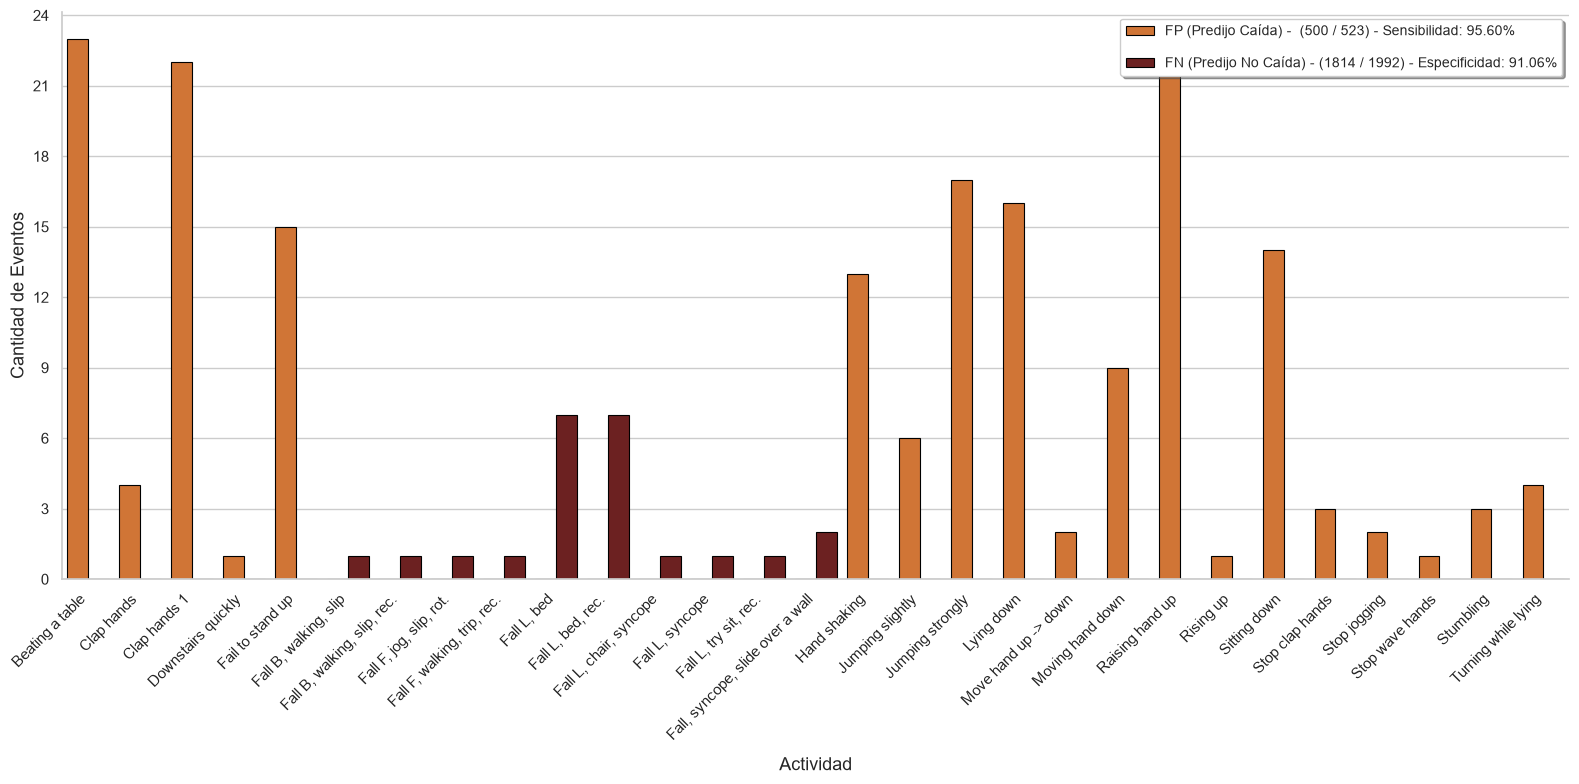

In [22]:
## Evaluando con los datos de validacion
model_perfom(model_merge_dataset, data_full, tags_full,threshold= 0.3,activity_names= activity_full)
plt.show()



In [ ]:
# model_merge_dataset.save(str(MODELS_DIR / "modelo_acelerometro.keras"))

## Sensibilidad al cambio de eje

Una de las características a tener en cuenta es que tan sensible es el modelo al cambio de ejes, por ejemplo si se coloca la orientación del sensor en forma alterada a la que se utilizó para obtener el dataset. Para obtener esto lo que se propone es utilizando el modelo previamente entrenado, correr un set de pruebas con las orientaciones modificadas.

![Cambio_orientacion.png](imgs/Cambio_orientacion.png)


In [24]:
def rotacion(datos, matriz_rot):
    if datos.ndim == 4:
        datos = datos[:,:,:,0]

    data = datos.copy()

    for indx, t in enumerate(data):
        data[indx] = t.dot(matriz_rot)

    data =  np.expand_dims(data, axis=-1)
    
    return data



matriz_rot = np.array([
    [-1,  0,  0],
    [ 0, -1,  0],
    [ 0,  0,  1]
])


data_rot = rotacion(data_val, matriz_rot)


model_perfom(red_cnn_completa, data_rot, y_val,threshold= 0.3)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.87      0.93      0.90       404
    FALL (1)       0.61      0.43      0.51        99

    accuracy                           0.83       503
   macro avg       0.74      0.68      0.70       503
weighted avg       0.82      0.83      0.82       503


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    376                 28
Real CAÍDA:       56                 43


Comparando el valor previo al cambio de orientacion y posterior se observa que el modelo es altamente dependiente de esta modificacion, siendo que es necesario poder ajustar los datos para que coincidad con los datos de entrenamiento